# Hyrje, të dhënat dhe validimi

**Lënda:** Machine Learning in Physics  
**Mjedisi:** Python, NumPy, pandas, Matplotlib dhe scikit-learn  
**Roli i notebook-ut:** mjeti kryesor i punës gjatë orës; leksioni i shkruar shërben për thellim teorik.

Ky laborator nis nga një pyetje që është më e rëndësishme se zgjedhja e vetë algoritmit: **si mund të dimë nëse një model ka mësuar një rregull që përgjithësohet, dhe jo thjesht ka përfituar nga mënyra si i kemi përgatitur të dhënat?** Në fizikë, një procedurë matjeje vlen vetëm nëse kontrollojmë burimet e informacionit, kalibrimin dhe pavarësinë e provës. E njëjta disiplinë duhet të zbatohet edhe në nxënien automatike.

Këtu ndarja trajnim–validim–provë, standardizimi, `Pipeline` dhe validimi i kryqëzuar nuk trajtohen si formalitete programimi. Ato janë pjesë e **protokollit eksperimental** të modelit.

Për këtë temë do t'u përgjigjemi sidomos tri pyetjeve:

1. Cila pjesë e të dhënave lejohet të ndikojë në përshtatjen e modelit?
2. Si e dallojmë një përmirësim real nga një rezultat tepër optimist i shkaktuar nga rrjedhja e informacionit?
3. Sa ndryshon vlerësimi ynë kur ndryshon ndarja e kampionit?

Ritmi i punës është: **parashiko → formulo matematikisht → implemento → ekzekuto → mat → interpreto → provo ta prishësh modelin**. Qelizat nuk duhen ekzekutuar mekanikisht njëra pas tjetrës. Para çdo eksperimenti duhet të kemi një pritshmëri dhe pas tij duhet të shpjegojmë mekanizmin që prodhoi rezultatin.


## Organizimi i seancës

| Koha | Veprimtaria | Rezultati i pritshëm |
|---:|---|---|
| 0–10 min | Pyetja shkencore dhe formulimi matematikor | Kuptimi i objektit që po modelojmë |
| 10–25 min | Zbatimi nga parimet e para | Lidhja ndërmjet formulës dhe algoritmit |
| 25–40 min | Eksperimenti numerik dhe figurat diagnostike | Kontrolli i sjelljes së modelit |
| 40–50 min | Krahasimi me implementimin profesional | Verifikimi i zbatimit dhe praktikës së mirë |
| 50–60 min | Interpretimi, kufizimet dhe një rast dështimi | Përfundim metodologjik, jo vetëm numerik |
| Pas orës | Punishtja dhe ushtrimet | Ndrysho një parametër, mat efektin dhe shpjego mekanizmin |

Kjo tabelë është orientuese. Nëse një diskutim fizik ose matematik është i frytshëm, është më e vlefshme të ndalemi te ai sesa të “mbarojmë” notebook-un.


## Rezultatet e të nxënit

Në fund të punës studenti duhet të jetë në gjendje të:

- Dalloj sample, feature dhe target.
- Ndaj trajnimin, validimin dhe provën sipas rolit të tyre.
- Shpjegoj data leakage me një shembull konkret.
- Përdor standardizimin pa parë test set-in.
- Interpretoj shpërndarjen e rezultateve të cross-validation.


### Para se të ekzekutojmë: Mjedisi llogaritës dhe riprodhueshmëria

Ngarkojmë bibliotekat që do të përdoren dhe fiksojmë `RANDOM_STATE = 42`. Ky seed nuk e bën problemin determinist në kuptimin fizik; ai thjesht na lejon të përsërisim të njëjtin eksperiment llogaritës dhe të diskutojmë metodën pa u hutuar nga ndryshime të rastësishme të mostrës.

**Parashikim para ekzekutimit.** Vlerësoni rendin e madhësisë dhe drejtimin e rezultatit përpara se ta llogarisë kompjuteri.


In [1]:
# Qëllimi i këtij blloku: Mjedisi llogaritës dhe riprodhueshmëria.
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
import numpy as np
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
import pandas as pd
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
import matplotlib.pyplot as plt
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
from pathlib import Path
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
import time

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

print("01 — Hyrje, të dhënat dhe validimi")
print("Seed:", RANDOM_STATE)

01 — Hyrje, të dhënat dhe validimi
Seed: 42


**Interpretim.** Një dalje numerike merr kuptim vetëm pasi krahasohet me shkallën e problemit, pritshmërinë teorike dhe një kontroll të pavarur kur është e mundur.


# 1. Problem konkret: kalibrimi i një sensori — CORE

Një sensor temperaturash jep një sinjal elektrik që ndryshon me temperaturën reale, por matjet
përmbajnë zhurmë. Çdo rresht i tabelës përfaqëson një **mostër (sample)**; tensioni, derivati lokal
dhe një temperaturë ndihmëse janë **veçori (features)**; temperatura reale është
**ndryshorja objektiv (target variable)**.

Në nxënien e mbikëqyrur (supervised learning) kemi çifte $(\mathbf{x}_i,y_i)$ dhe kërkojmë një
funksion $\hat y=f(\mathbf{x};\theta)$. Qëllimi nuk është të shpjegojmë vetëm të dhënat e njohura,
por të përgjithësojmë te matje të reja.

### Para se të ekzekutojmë: Ndërtimi i një eksperimenti sintetik

Fillojmë me një sensor të thjeshtë sepse na lejon të dimë “të vërtetën” e sistemit që po simulojmë. Krijojmë temperaturën reale, sinjalin e sensorit dhe zhurmën në mënyrë të kontrolluar. Kjo është e dobishme pedagogjikisht: kur më vonë shohim gabimin e modelit, dimë nëse vjen nga zhurma, nga ndarja e të dhënave apo nga një zgjedhje metodologjike. Tabela `DataFrame` e bën gjithashtu të dukshme dallimin ndërmjet veçorive dhe target-it.

**Parashikim para ekzekutimit.** Para se të gjenerohen të dhënat, identifikoni strukturën që është futur në modelin sintetik dhe cilën pjesë ia lëmë zhurmës.


In [2]:
# Qëllimi i këtij blloku: Ndërtimi i një eksperimenti sintetik.
n = 320
T_true = rng.uniform(-10, 50, n)
# Gjenerojmë të dhëna të kontrolluara që na lejojnë të dimë strukturën që duhet të zbulojë modeli.
voltage = 0.04*T_true + 1.5 + rng.normal(0, 0.08, n)
# Gjenerojmë të dhëna të kontrolluara që na lejojnë të dimë strukturën që duhet të zbulojë modeli.
aux = 0.3*np.sin(T_true/8) + rng.normal(0, 0.05, n)
X = np.c_[voltage, aux]
# Gjenerojmë të dhëna të kontrolluara që na lejojnë të dimë strukturën që duhet të zbulojë modeli.
y = T_true + rng.normal(0, 0.7, n)

df = pd.DataFrame({"voltage_V": voltage, "aux_signal": aux, "temperature_C": y})
df.head()

,voltage_V,aux_signal,temperature_C
0,3.004107,-0.348306,36.705383
1,2.291893,0.146724,13.778817
2,3.254828,-0.185953,40.309451
3,2.808810,-0.095660,32.158320
4,1.465540,-0.175448,-4.015089


### Para se të ekzekutojmë: Vizualizimi i parë i marrëdhënies fizike

Para çdo algoritmi duhet të shohim të dhënat. Grafiku na tregon nëse ekziston një prirje e arsyeshme, nëse ka outlier-a dhe nëse një model i thjeshtë mund të jetë i përshtatshëm. Në fizikë, ky hap korrespondon me inspektimin fillestar të matjeve përpara përshtatjes së një ligji.

**Parashikim para ekzekutimit.** Vendosni çfarë forme duhet të ketë figura nëse argumenti teorik është i saktë. Grafiku përdoret për të testuar një pritshmëri, jo vetëm për ta ilustruar.


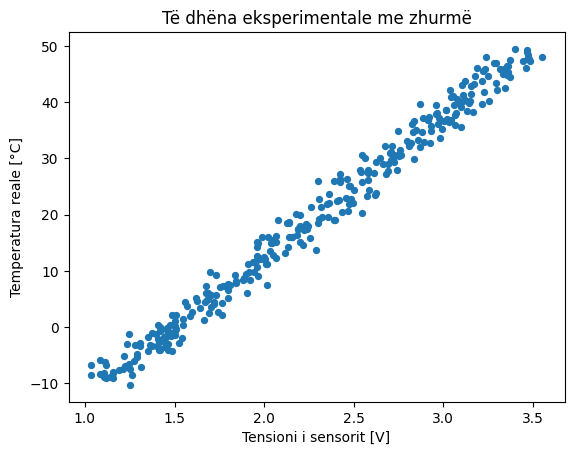

In [3]:
# Qëllimi i këtij blloku: Vizualizimi i parë i marrëdhënies fizike.
# Ndërtojmë një figurë diagnostike; grafiku është pjesë e analizës, jo dekorim.
fig, ax = plt.subplots()
ax.scatter(df["voltage_V"], df["temperature_C"], s=18)
ax.set_xlabel("Tensioni i sensorit [V]")
ax.set_ylabel("Temperatura reale [°C]")
ax.set_title("Të dhëna eksperimentale me zhurmë")
plt.show()

**Interpretim.** Figura duhet lexuar si test i një hipoteze të vogël: a përputhet forma e vëzhguar me atë që parashikuam nga matematika?


**Interpretim.** Boshti horizontal është një veçori e matur; boshti vertikal është madhësia që duam të parashikojmë. Përhapja rreth prirjes lineare përfaqëson zhurmë matëse dhe efekte të pamodeluara.

Në një analizë reale ky interpretim duhet të shoqërohet me kontroll të njësive, madhësive karakteristike dhe hipotezave që lejojnë kalimin nga një tregues numerik te një përfundim fizik.

# 2. Ndarja trajnim–validim–provë — CORE

Bashkësia e trajnimit (training set) përdoret për të përshtatur parametrat. Bashkësia e validimit
(validation set) ndihmon në zgjedhjen e modelit ose hiperparametrave. Bashkësia e provës (test set)
duhet të mbetet e paprekur deri në fund.

Kjo ndarje është pjesë e metodës shkencore: modeli testohet mbi të dhëna që nuk kanë marrë pjesë
në vendimet e ndërtimit të tij.

### Para se të ekzekutojmë: Ndarja e të dhënave

Tani e ndajmë problemin në tre role të ndryshme. Trajnimi përshtat parametrat, validimi mbështet zgjedhjet tona dhe prova është kontrolli final. Kjo ndarje është e nevojshme sepse një model i vlerësuar vazhdimisht mbi të njëjtat të dhëna mund të përshtatet edhe me vetë procesin e vlerësimit.

**Parashikim para ekzekutimit.** Para se të shohim rezultatet, mendoni nëse ndarja e zgjedhur ruan përfaqësimin e klasave dhe nëse është e justifikuar nga mënyra si do të përdoret modeli në praktikë.


In [4]:
# Qëllimi i këtij blloku: Ndarja e të dhënave.
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
from sklearn.model_selection import train_test_split
# Ndajmë të dhënat në mënyrë të riprodhueshme; test-i nuk përdoret për trajnim.
X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.4, random_state=RANDOM_STATE)
# Ndajmë të dhënat në mënyrë të riprodhueshme; test-i nuk përdoret për trajnim.
X_valid, X_test, y_valid, y_test = train_test_split(X_tmp, y_tmp, test_size=0.5, random_state=RANDOM_STATE)

print(X_train.shape, X_valid.shape, X_test.shape)

(192, 2) (64, 2) (64, 2)


**Interpretim.** Ndarja e të dhënave përcakton çfarë quajmë “e panjohur”. Në probleme reale, ndarja sipas kohës, instrumentit ose eksperimentit mund të jetë më e fortë se ndarja rastësore.


### Para se të ekzekutojmë: Kontrolli i shpërndarjeve

Ndarja është statistikisht e dobishme vetëm nëse kuptojmë çfarë përfaqëson secila pjesë. Histogramet na lejojnë të kontrollojmë nëse kemi krijuar pa dashje një train/test shift. Në të dhëna reale ky kontroll duhet bërë edhe për kohën, instrumentin, stacionin ose serinë eksperimentale.

**Parashikim para ekzekutimit.** Vendosni çfarë forme duhet të ketë figura nëse argumenti teorik është i saktë. Grafiku përdoret për të testuar një pritshmëri, jo vetëm për ta ilustruar.


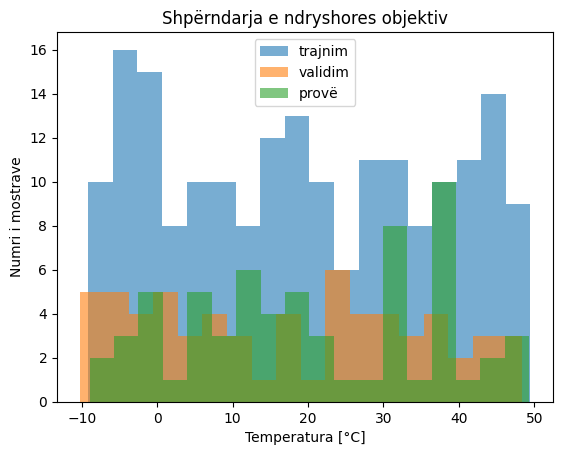

In [5]:
# Qëllimi i këtij blloku: Kontrolli i shpërndarjeve.
# Ndërtojmë një figurë diagnostike; grafiku është pjesë e analizës, jo dekorim.
fig, ax = plt.subplots()
ax.hist(y_train, bins=18, alpha=0.6, label="trajnim")
ax.hist(y_valid, bins=18, alpha=0.6, label="validim")
ax.hist(y_test, bins=18, alpha=0.6, label="provë")
ax.set_xlabel("Temperatura [°C]")
ax.set_ylabel("Numri i mostrave")
ax.legend()
ax.set_title("Shpërndarja e ndryshores objektiv")
plt.show()

**Interpretim.** Figura duhet lexuar si test i një hipoteze të vogël: a përputhet forma e vëzhguar me atë që parashikuam nga matematika?


**Interpretim.** Ndarjet nuk duhet të kenë shpërndarje krejt të ndryshme pa arsye fizike. Në probleme reale, ndarja sipas kohës ose sipas instrumentit mund të jetë më e drejtë se një ndarje plotësisht e rastësishme.

Në një analizë reale ky interpretim duhet të shoqërohet me kontroll të njësive, madhësive karakteristike dhe hipotezave që lejojnë kalimin nga një tregues numerik te një përfundim fizik.

# 3. Standardizimi dhe rrjedhja e informacionit — CORE

Standardizimi (standardization) përdor
$$
z_j=\frac{x_j-\mu_j}{\sigma_j}.
$$
Vlerat $\mu_j$ dhe $\sigma_j$ duhet të llogariten **vetëm nga bashkësia e trajnimit**. Nëse
përdorim të gjithë të dhënat përpara ndarjes, informacion nga prova futet në procesin e trajnimit.
Kjo quhet **rrjedhje informacioni (data leakage)**.

### Para se të ekzekutojmë: Eksperimenti i rrjedhjes së informacionit

Ky është një eksperiment i qëllimshëm metodologjik: bëjmë fillimisht një gjë të gabuar dhe pastaj versionin korrekt. Standardizimi mbi të gjithë dataset-in lejon që mesatarja dhe devijimi standard i testit të ndikojnë transformimin. Pipeline-i korrekt i mëson këto statistika vetëm nga trajnimi. Edhe kur diferenca numerike duket e vogël, parimi është themelor.

**Parashikim para ekzekutimit.** Cilat statistika duhet të mësohen vetëm nga trajnimi? Parashikoni çfarë rrezikojmë nëse standardizimi ose një transformim tjetër sheh edhe test set-in.


In [6]:
# Qëllimi i këtij blloku: Eksperimenti i rrjedhjes së informacionit.
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
from sklearn.preprocessing import StandardScaler
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
from sklearn.linear_model import Ridge
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
from sklearn.metrics import mean_squared_error

# Gabim: standardizim para ndarjes
# Përshtatim standardizimin vetëm mbi të dhënat e trajnimit për të shmangur leakage.
scaler_wrong = StandardScaler().fit(X)
X_all_scaled = scaler_wrong.transform(X)
# Ndajmë të dhënat në mënyrë të riprodhueshme; test-i nuk përdoret për trajnim.
Xtr_w, Xte_w, ytr_w, yte_w = train_test_split(X_all_scaled, y, test_size=0.25, random_state=RANDOM_STATE)
# Përshtatim parametrat e modelit mbi bashkësinë e trajnimit.
m_wrong = Ridge(alpha=1.0).fit(Xtr_w, ytr_w)
# Llogarisim parashikimet mbi të dhëna që nuk përdoren për të ndryshuar parametrat e modelit.
rmse_wrong = mean_squared_error(yte_w, m_wrong.predict(Xte_w))**0.5

# Saktë: scaler përshtatet vetëm mbi trajnim
# Ndajmë të dhënat në mënyrë të riprodhueshme; test-i nuk përdoret për trajnim.
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=RANDOM_STATE)
# Përshtatim standardizimin vetëm mbi të dhënat e trajnimit për të shmangur leakage.
scaler = StandardScaler().fit(Xtr)
# Përshtatim parametrat e modelit mbi bashkësinë e trajnimit.
m_right = Ridge(alpha=1.0).fit(scaler.transform(Xtr), ytr)
# Llogarisim parashikimet mbi të dhëna që nuk përdoren për të ndryshuar parametrat e modelit.
rmse_right = mean_squared_error(yte, m_right.predict(scaler.transform(Xte)))**0.5
rmse_wrong, rmse_right

(2.0856033751589367, 2.0856185055961545)

**Interpretim.** Ky hap është i vlefshëm vetëm nëse transformimet janë përshtatur pa përdorur informacion nga prova. Një score më i lartë pas rrjedhjes së informacionit nuk është përmirësim shkencor; është shkelje e protokollit të validimit.


### Para se të ekzekutojmë: Krahasimi grafik i dy procedurave

Një tabelë me dy numra mund të kalojë pa u vënë re; grafiku e bën ndryshimin metodologjik të dukshëm. Këtu duhet të theksohet se një rezultat më i mirë i procedurës me leakage nuk është sukses, por simptomë e një eksperimenti të padrejtë.

**Parashikim para ekzekutimit.** Vendosni çfarë forme duhet të ketë figura nëse argumenti teorik është i saktë. Grafiku përdoret për të testuar një pritshmëri, jo vetëm për ta ilustruar.


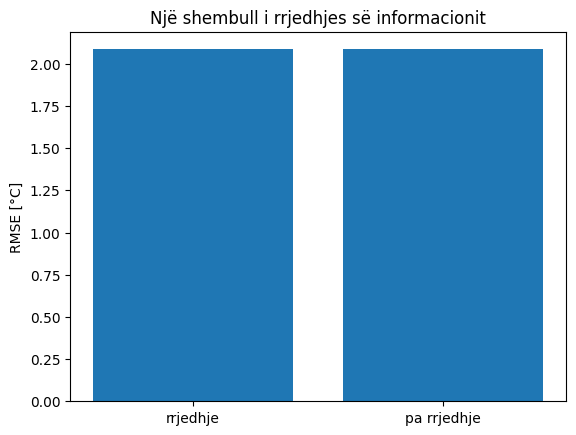

In [7]:
# Qëllimi i këtij blloku: Krahasimi grafik i dy procedurave.
# Ndërtojmë një figurë diagnostike; grafiku është pjesë e analizës, jo dekorim.
fig, ax = plt.subplots()
ax.bar(["rrjedhje", "pa rrjedhje"], [rmse_wrong, rmse_right])
ax.set_ylabel("RMSE [°C]")
ax.set_title("Një shembull i rrjedhjes së informacionit")
plt.show()

**Interpretim.** Figura duhet lexuar si test i një hipoteze të vogël: a përputhet forma e vëzhguar me atë që parashikuam nga matematika?


**Interpretim.** Në këtë shembull të thjeshtë diferenca mund të jetë e vogël, por parimi është kritik. Në probleme me përzgjedhje veçorish, imputim ose shumë hiperparametra, rrjedhja mund të japë rezultate dukshëm tepër optimiste.

Në një analizë reale ky interpretim duhet të shoqërohet me kontroll të njësive, madhësive karakteristike dhe hipotezave që lejojnë kalimin nga një tregues numerik te një përfundim fizik.

# 4. Pipeline dhe validim i kryqëzuar — CORE

### Para se të ekzekutojmë: Pipeline dhe validimi i kryqëzuar

Validimi i kryqëzuar përsërit procesin e vlerësimit mbi ndarje të ndryshme. Duke futur standardizimin dhe modelin në një `Pipeline`, sigurojmë që çdo fold të sillet si një eksperiment i vogël i pavarur: scaler-i mësohet vetëm mbi pjesën e trajnimit të atij fold-i.

**Parashikim para ekzekutimit.** Nuk presim që të gjitha fold-et të japin të njëjtën vlerë. Parashikoni nëse variacioni do të jetë i vogël apo i madh dhe çfarë do të nënkuptonte secili rast.


In [8]:
# Qëllimi i këtij blloku: Pipeline dhe validimi i kryqëzuar.
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
from sklearn.pipeline import make_pipeline
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
from sklearn.model_selection import KFold, cross_val_score

pipe = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
# Vlerësojmë modelin në disa ndarje për të matur si performancën ashtu edhe ndryshueshmërinë.
scores = -cross_val_score(pipe, X, y, cv=cv, scoring="neg_root_mean_squared_error")

print("RMSE për çdo fold:", np.round(scores, 3))
print("Mesatarja ± std:", scores.mean(), scores.std())

RMSE për çdo fold: [2.189 2.218 2.151 2.301 1.769]
Mesatarja ± std: 2.1255897998021966 0.18520479299614526


**Interpretim.** Mesatarja tregon performancën tipike, ndërsa shpërndarja ndër fold-e tregon stabilitetin. Raportimi i vetëm mesatares fsheh një pjesë të pasigurisë metodologjike.


### Para se të ekzekutojmë: Ndryshueshmëria ndërmjet fold-eve

Nuk raportojmë vetëm mesataren; shohim edhe shpërndarjen. Nëse fold-et japin rezultate shumë të ndryshme, modeli ose dataset-i nuk është i qëndrueshëm. Ky informacion është po aq i rëndësishëm sa score-i mesatar, sepse tregon sa i ndjeshëm është përfundimi ndaj mostrimit.

**Parashikim para ekzekutimit.** Vendosni çfarë forme duhet të ketë figura nëse argumenti teorik është i saktë. Grafiku përdoret për të testuar një pritshmëri, jo vetëm për ta ilustruar.


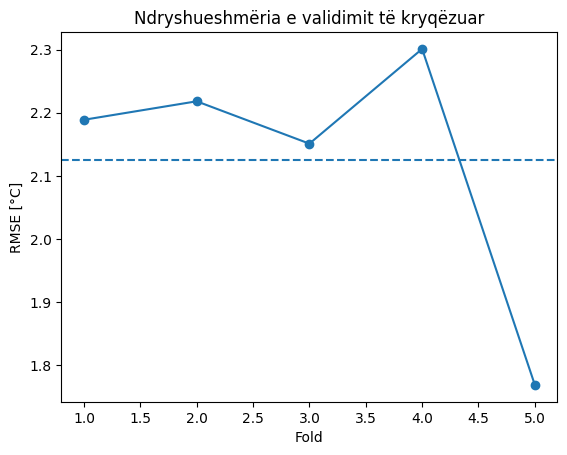

In [9]:
# Qëllimi i këtij blloku: Ndryshueshmëria ndërmjet fold-eve.
# Ndërtojmë një figurë diagnostike; grafiku është pjesë e analizës, jo dekorim.
fig, ax = plt.subplots()
ax.plot(np.arange(1, len(scores)+1), scores, marker="o")
ax.axhline(scores.mean(), linestyle="--")
ax.set_xlabel("Fold")
ax.set_ylabel("RMSE [°C]")
ax.set_title("Ndryshueshmëria e validimit të kryqëzuar")
plt.show()

**Interpretim.** Figura duhet lexuar si test i një hipoteze të vogël: a përputhet forma e vëzhguar me atë që parashikuam nga matematika?


**Interpretim.** Një rezultat i vetëm fsheh pasigurinë që vjen nga ndarja e të dhënave. Shpërndarja e rezultateve ndërmjet fold-eve na tregon sa i qëndrueshëm është vlerësimi.

Në një analizë reale ky interpretim duhet të shoqërohet me kontroll të njësive, madhësive karakteristike dhe hipotezave që lejojnë kalimin nga një tregues numerik te një përfundim fizik.

---
## Deri këtu: materiali bazë për orën mësimore

Në një seancë rreth 60 minuta, zakonisht ndalemi këtu. Seksionet që vijojnë janë për thellim,
ushtrime të pavarura dhe eksperimentim.

# 5. Shembull i dytë: të dhëna jo-fizike — EXTENDED

I njëjti disiplinim metodologjik përdoret në mjekësi, financë ose energji: çdo hap parapërpunimi duhet të mësohet vetëm nga të dhënat e trajnimit.

### Para se të ekzekutojmë: Transferimi i metodës jashtë fizikës

Përdorim një dataset mjekësor jo për të ndryshuar temë, por për të treguar se protokolli mbetet i njëjtë. Standardizimi, pipeline-i dhe cross-validation nuk janë teknika specifike për sensorët fizikë; janë pjesë e metodologjisë së përgjithshme të nxënies automatike.

**Parashikim para ekzekutimit.** Nuk presim që të gjitha fold-et të japin të njëjtën vlerë. Parashikoni nëse variacioni do të jetë i vogël apo i madh dhe çfarë do të nënkuptonte secili rast.


In [10]:
# Qëllimi i këtij blloku: Transferimi i metodës jashtë fizikës.
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
from sklearn.datasets import load_breast_cancer
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
from sklearn.linear_model import LogisticRegression
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
from sklearn.model_selection import cross_val_score
data = load_breast_cancer()
pipe_cls = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000))
# Vlerësojmë modelin në disa ndarje për të matur si performancën ashtu edhe ndryshueshmërinë.
acc = cross_val_score(pipe_cls, data.data, data.target, cv=5, scoring="accuracy")
acc.mean(), acc.std()

(np.float64(0.9806862288464524), np.float64(0.006539441283506109))

# 6. Diagnostikë: çfarë mund të shkojë keq? — EXTENDED

Gabimet e zakonshme janë: ndarje jo përfaqësuese, rrjedhje informacioni, përdorim i testit për
zgjedhje hiperparametrash dhe ngatërrim i rezultateve të trajnimit me aftësinë e përgjithësimit.

### Para se të ekzekutojmë: Një ndarje e keqe e qëllimshme

Këtu krijojmë me vetëdije një train/test shift ekstrem duke ndarë target-in sipas madhësisë. Qëllimi është të kuptojmë se një ndarje mund të jetë teknikisht e vlefshme në kod dhe shkencërisht e pavlefshme. Dizajni i ndarjes duhet të pasqyrojë mënyrën reale se si modeli do të përdoret.

**Parashikim para ekzekutimit.** Vendosni çfarë forme duhet të ketë figura nëse argumenti teorik është i saktë. Grafiku përdoret për të testuar një pritshmëri, jo vetëm për ta ilustruar.


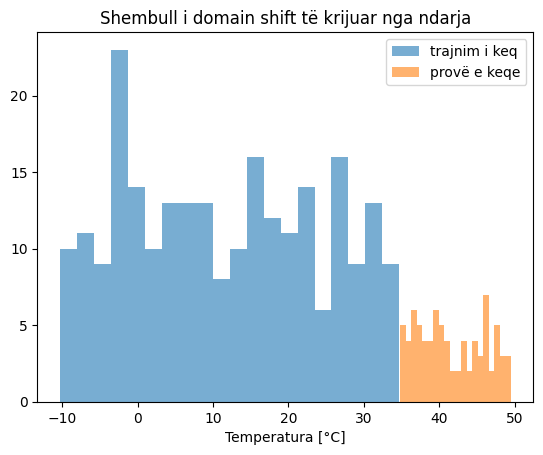

In [11]:
# Qëllimi i këtij blloku: Një ndarje e keqe e qëllimshme.
# Vizualizojmë një ndarje të keqe të qëllimshme sipas vlerës së target-it
# Renditja përdoret për të identifikuar fqinjët ose komponentët sipas kriterit përkatës.
order = np.argsort(y)
split = int(0.75*len(y))
y_bad_train = y[order[:split]]
y_bad_test = y[order[split:]]

# Ndërtojmë një figurë diagnostike; grafiku është pjesë e analizës, jo dekorim.
fig, ax = plt.subplots()
ax.hist(y_bad_train, bins=20, alpha=0.6, label="trajnim i keq")
ax.hist(y_bad_test, bins=20, alpha=0.6, label="provë e keqe")
ax.legend()
ax.set_xlabel("Temperatura [°C]")
ax.set_title("Shembull i domain shift të krijuar nga ndarja")
plt.show()

**Interpretim.** Figura duhet lexuar si test i një hipoteze të vogël: a përputhet forma e vëzhguar me atë që parashikuam nga matematika?


## Punishtja — ndrysho, mat dhe shpjego

Në këtë pjesë nuk kërkohet ekzekutim pasiv. Për çdo eksperiment:

1. shkruani paraprakisht çfarë prisni të ndodhë;
2. ndryshoni **vetëm një** element në të njëjtën kohë;
3. ruani metrikën ose figurën që ndryshon;
4. shpjegoni mekanizmin matematik ose statistikor;
5. dalloni qartë atë që tregon eksperimenti nga ajo që **nuk** mund të përfundohet prej tij.

### Pyetje për diskutim

1. Pse test set-i duhet të mbetet i paprekur deri në fund?
2. Në cilat raste ndarja rastësore është fizikisht e gabuar?
3. Pse `Pipeline` është më shumë se një lehtësi programimi?
4. Si do ta dallonit një model të paqëndrueshëm nga një dataset jo përfaqësues?


# Ushtrime — PLAYGROUND

        ## A. Ushtrime të shkurtra
        1. Shpjegoni pse një `Pipeline` parandalon rrjedhjen e informacionit.
2. Ndryshoni raportin trajnim/provë dhe vëzhgoni ndryshimin e RMSE.
3. Krahasoni 5-fold dhe 10-fold cross-validation.
4. Shtoni një veçori plotësisht të rastësishme dhe shihni nëse përmirëson modelin.

        ## B. Ushtrim i plotë
        Ndërtoni një pipeline për një problem klasifikimi, përfshini standardizimin dhe raportoni mesataren dhe devijimin standard të F1 në validim të kryqëzuar.

        ## C. Playground
        Ndryshoni seed, madhësinë e mostrës dhe nivelin e zhurmës së sensorit.

In [12]:
# TODO / PLAYGROUND
# Ndryshoni parametrat, shtoni grafikë ose krahasoni modele të tjera.

## Përmbledhje konceptuale e kapitullit

Notebook-u **Hyrje, të dhënat dhe validimi** duhet të lihet me një ide të qartë: algoritmi është vetëm një hallkë e arsyetimit. Para tij kemi zgjedhjen e përfaqësimit dhe hipotezat mbi të dhënat; pas tij kemi validimin, diagnostikën dhe interpretimin. Nëse një student mund të ekzekutojë të gjitha qelizat por nuk mund të shpjegojë pse secila prej tyre është e nevojshme, atëherë puna llogaritëse nuk është përfunduar ende.

Për studim të mëtejshëm, rikthehuni te shënimet e leksionit për derivimet e plota dhe përdoreni këtë notebook si laborator ku këto ide testohen numerikisht.

### Zgjidhje orientuese për instruktorin
- `Pipeline` përshtat transformimet vetëm brenda fold-it të trajnimit; kështu statistikat e testit nuk rrjedhin në model.
- Me më pak të dhëna trajnimi rritet varianca e vlerësimit; me më shumë të dhëna testi rritet saktësia e vlerësimit të performancës, por zvogëlohet trajnimi.
- 10-fold zakonisht ka bias pak më të vogël por kosto më të lartë dhe rezultate fold-esh më të korreluara.
- Një veçori plotësisht e rastësishme nuk duhet të japë përmirësim të qëndrueshëm jashtë kampionit.

## Kontrolli përfundimtar

- [ ] Dalloj sample, feature dhe target.
- [ ] Ndaj trajnimin, validimin dhe provën sipas rolit të tyre.
- [ ] Shpjegoj data leakage me një shembull konkret.
- [ ] Përdor standardizimin pa parë test set-in.
- [ ] Interpretoj shpërndarjen e rezultateve të cross-validation.
